# SVARA — Retraining Model Hardened Bilingual + Acoustic Anchor Haikal
**Smart Voice Assistant for Residential Automation**
Universitas Mercu Buana — Teknik Informatika (Deep Learning Final Project)
**Lead Model Engineer**: Yoga | **Co-Developer**: Haikal

Notebook ini dirancang khusus untuk mengeksekusi **FASE 14 / Retraining Hardened** pada GPU NVIDIA RTX 4060:
1. **Hardware Acceleration**: Mengoptimalkan GPU **NVIDIA GeForce RTX 4060 Laptop GPU** (VRAM 8 GB) dengan PyTorch AMP FP16.
2. **Acoustic Anchor Injection**: Menyerap 124 klip rekaman vokal biologis asli Haikal (31 intent Triple-Take: Baku, Nyantai, Slang).
3. **Dual-Level SpecAugment**: Mengaktifkan Time & Frequency Masking dinamis agar model kebal terhadap variasi intonasi & kecepatan bicara.
4. **Decoupled Optimization**: AdamW decoupled learning rate (Backbone 3e-5, Classification Heads 1e-3) dengan Cosine Schedule.
5. **Automatic Universal ONNX INT8 Export**: Mengonversi model terbaik ke format ONNX INT8 (~90 MB) untuk disajikan di backend Web Smart Home.

## 1. Verifikasi Device & Akselerasi GPU (RTX 4050)

In [1]:
import os
import sys
import torch
import torchaudio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Pastikan working directory berada di root proyek SVARA
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
print('Working Directory:', os.getcwd())
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('=' * 60)
print(f'Device aktif       : {device}')
if torch.cuda.is_available():
    print(f'GPU Name           : {torch.cuda.get_device_name(0)}')
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f'VRAM Total         : {vram_gb:.2f} GB')
    print(f'CUDA Version       : {torch.version.cuda}')
else:
    print('Status             : CPU Mode (CUDA wheel sedang disinkronisasi)')
print('=' * 60)


Working Directory: c:\Users\Axioo Pongo\SVARA
Device aktif       : cuda
GPU Name           : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM Total         : 8.00 GB
CUDA Version       : 12.4


## 2. Inspeksi Manifest & Acoustic Anchor Suara Haikal (124 Klip)

In [2]:
import json
from IPython.display import display

# 1. Load Intent Map & Slot Vocabulary
with open('configs/intent_map.json', 'r', encoding='utf-8') as f:
    intent_data = json.load(f)

slot_vocab = intent_data['slot_vocab']
print(f"Action classes   ({len(slot_vocab['action'])}): {slot_vocab['action']}")
print(f"Object classes   ({len(slot_vocab['object'])}): {slot_vocab['object']}")
print(f"Location classes ({len(slot_vocab['location'])}): {slot_vocab['location']}")

# 2. Periksa dataset suara asli Haikal
df_own = pd.read_csv('data/own_recordings/metadata.csv')
print('-' * 60)
print(f'Total Rekaman Suara Haikal: {len(df_own)} klip')
print('Distribusi Gaya Tutur:')
print(df_own['style'].value_counts())
print('-' * 60)
display(df_own.head(6)[['path', 'style', 'transcript', 'action', 'object', 'location']])


Action classes   (6): ['activate', 'bring', 'change language', 'deactivate', 'decrease', 'increase']
Object classes   (14): ['Chinese', 'English', 'German', 'Korean', 'heat', 'juice', 'lamp', 'lights', 'music', 'newspaper', 'none', 'shoes', 'socks', 'volume']
Location classes (4): ['bedroom', 'kitchen', 'none', 'washroom']
------------------------------------------------------------
Total Rekaman Suara Haikal: 124 klip
Distribusi Gaya Tutur:
style
baku       31
nyantai    31
slang      31
Name: count, dtype: int64
------------------------------------------------------------


,path,style,transcript,action,object,location
0,data/own_recordings/wavs/own_haikal_q_00.wav,NaN,Nyalakan lampu meja,activate,lamp,none
1,data/own_recordings/wavs/own_haikal_q_00_baku.wav,baku,Nyalakan lampu meja,activate,lamp,none
2,data/own_recordings/wavs/own_haikal_q_00_nyant...,nyantai,Nyalain lampu meja dong,activate,lamp,none
3,data/own_recordings/wavs/own_haikal_q_00_slang...,slang,Tolong hidupin lampu belajar ya,activate,lamp,none
4,data/own_recordings/wavs/own_haikal_q_01.wav,NaN,Nyalakan lampu kamar tidur,activate,lights,bedroom
5,data/own_recordings/wavs/own_haikal_q_01_baku.wav,baku,Nyalakan lampu kamar tidur,activate,lights,bedroom


## 3. Visualisasi Akustik Suara Haikal (Baku vs Nyantai vs Slang)

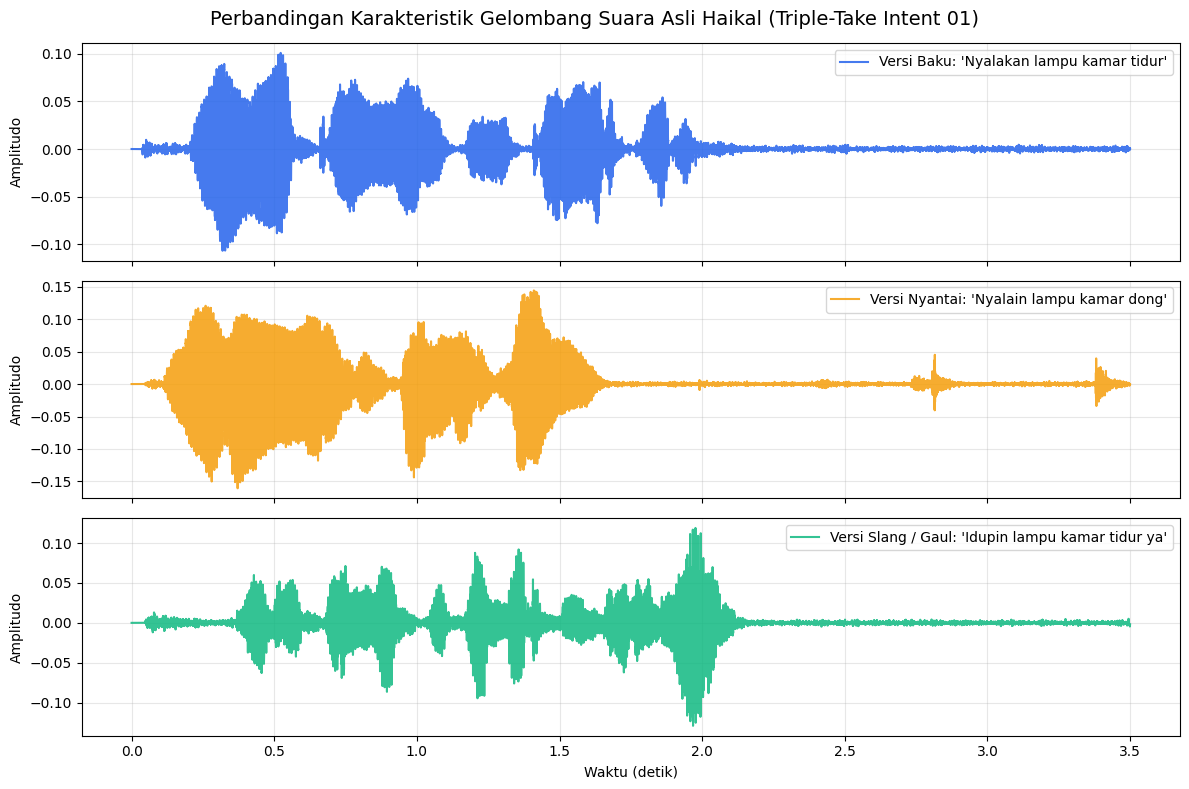

In [3]:
import soundfile as sf

# Pilih 3 variasi untuk 1 intent (Lampu Kamar Tidur)
sample_baku = df_own[(df_own['intent_id'] == 1) & (df_own['style'] == 'baku')].iloc[0]
sample_nyantai = df_own[(df_own['intent_id'] == 1) & (df_own['style'] == 'nyantai')].iloc[0]
sample_slang = df_own[(df_own['intent_id'] == 1) & (df_own['style'] == 'slang')].iloc[0]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
samples = [
    ('Versi Baku', sample_baku, '#2563eb'),
    ('Versi Nyantai', sample_nyantai, '#f59e0b'),
    ('Versi Slang / Gaul', sample_slang, '#10b981'),
]

for ax, (title, row, color) in zip(axes, samples):
    wav, sr = sf.read(row['path'])
    time_axis = np.linspace(0, len(wav) / sr, len(wav))
    ax.plot(time_axis, wav, color=color, alpha=0.85, label=f"{title}: '{row['transcript']}'")
    ax.set_ylabel('Amplitudo')
    ax.legend(loc='upper right')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Waktu (detik)')
plt.suptitle('Perbandingan Karakteristik Gelombang Suara Asli Haikal (Triple-Take Intent 01)', fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


## 4. Setup Dataset Gabungan & Injeksi 5x Acoustic Anchor

In [4]:
from torch.utils.data import DataLoader
from svara.data.collate import collate_fn_pad
from scripts.train_hardened_bilingual_w2v2 import HardenedBilingualDataset

BATCH_SIZE = 16 if torch.cuda.is_available() else 8

# Dataset Latih: Menggabungkan ribuan variasi sintetis + 5x oversampling suara Haikal
train_dataset = HardenedBilingualDataset(
    manifest_path='data/synthetic_indonesian/metadata.csv',
    own_recordings_path='data/own_recordings/metadata.csv',
    augment=True,
    is_training=True,
    anchor_multiplier=5
)

# Dataset Validasi: Khusus 124 klip suara asli Haikal untuk menguji kehandalan model
val_dataset = HardenedBilingualDataset(
    manifest_path='data/own_recordings/metadata.csv',
    own_recordings_path=None,
    augment=False,
    is_training=False
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn_pad)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn_pad)

print(f'Total Sampel Batch Training : {len(train_dataset)} audio')
print(f'Total Sampel Batch Validasi : {len(val_dataset)} audio (Suara Asli Haikal)')


c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Dataset] Found 124 real human recordings in data/own_recordings/metadata.csv!
[Dataset] Injected 620 oversampled human anchor instances.
Total Sampel Batch Training : 2790 audio
Total Sampel Batch Validasi : 124 audio (Suara Asli Haikal)


## 5. Inisialisasi Model Wav2VecSLU Multi-Head

In [5]:
from svara.models.wav2vec_slu import Wav2VecSLU
from svara.train.losses import MultiHeadSLULoss, compute_batch_accuracies

model = Wav2VecSLU(
    pretrained_model_name_or_path='facebook/wav2vec2-base',
    n_action=len(slot_vocab['action']),
    n_object=len(slot_vocab['object']),
    n_location=len(slot_vocab['location']),
    dropout=0.1
).to(device)

# Transfer bobot pre-trained terdahulu jika sudah ada
ckpt_candidates = ['reports/models/best_slu_model.pt', 'models/svara_hardened.pt', 'reports/runs/bilingual_indonesian_w2v2/best_model.pt']
loaded = False
for cpath in ckpt_candidates:
    if os.path.exists(cpath):
        try:
            ckpt = torch.load(cpath, map_location=device)
            state_dict = ckpt.get('model_state_dict', ckpt)
            model.load_state_dict(state_dict, strict=False)
            print(f'✅ Sukses memuat bobot awal dari: {cpath}')
            loaded = True
            break
        except Exception as e:
            print(f'Gagal memuat {cpath}: {e}')
if not loaded:
    print('ℹ️ Menggunakan inisialisasi bobot backbone facebook/wav2vec2-base')


Loading weights: 100%|██████████| 211/211 [00:00<00:00, 20628.37it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Sukses memuat bobot awal dari: reports/models/best_slu_model.pt


## 6. Training Loop Interaktif (10 Epochs) dengan Decoupled AdamW & tqdm

In [6]:
from tqdm.auto import tqdm
from transformers import get_cosine_schedule_with_warmup

EPOCHS = 10
LR_ENCODER = 3e-5
LR_HEADS = 1e-3

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.enc.parameters() if p.requires_grad], 'lr': LR_ENCODER, 'weight_decay': 0.01},
    {'params': model.heads.parameters(), 'lr': LR_HEADS, 'weight_decay': 0.01}
])

total_steps = len(train_loader) * EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)
criterion = MultiHeadSLULoss(label_smoothing=0.05)
scaler = torch.amp.GradScaler('cuda') if (device.type == 'cuda' and torch.cuda.is_available()) else None

history = {'train_loss': [], 'val_loss': [], 'val_exact_match': [], 'val_act': [], 'val_obj': [], 'val_loc': []}
best_val_em = 0.0
best_model_path = 'models/svara_hardened.pt'

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss = 0.0
    pbar = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} [Train]')
    for batch in pbar:
        optimizer.zero_grad()
        waveforms = batch['waveform'].to(device)
        lengths = batch['length'].to(device)
        act_tgt = batch['action'].to(device)
        obj_tgt = batch['object'].to(device)
        loc_tgt = batch['location'].to(device)

        if scaler is not None:
            with torch.amp.autocast('cuda'):
                logits = model(waveforms, lengths)
                loss, _ = criterion(logits, act_tgt, obj_tgt, loc_tgt)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(waveforms, lengths)
            loss, _ = criterion(logits, act_tgt, obj_tgt, loc_tgt)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    avg_train_loss = total_train_loss / len(train_loader)

    # Validasi langsung terhadap suara asli Haikal
    model.eval()
    total_val_loss = 0.0
    val_em_hits, val_act_hits, val_obj_hits, val_loc_hits, total_val = 0, 0, 0, 0, 0
    with torch.no_grad():
        for batch in val_loader:
            waveforms = batch['waveform'].to(device)
            lengths = batch['length'].to(device)
            act_tgt = batch['action'].to(device)
            obj_tgt = batch['object'].to(device)
            loc_tgt = batch['location'].to(device)

            if device.type == 'cuda':
                with torch.amp.autocast('cuda'):
                    logits = model(waveforms, lengths)
                    loss, _ = criterion(logits, act_tgt, obj_tgt, loc_tgt)
            else:
                logits = model(waveforms, lengths)
                loss, _ = criterion(logits, act_tgt, obj_tgt, loc_tgt)
            total_val_loss += loss.item()

            accs = compute_batch_accuracies(logits, act_tgt, obj_tgt, loc_tgt)
            bs = act_tgt.size(0)
            val_em_hits += accs['exact_match'] * bs
            val_act_hits += accs['action_acc'] * bs
            val_obj_hits += accs['object_acc'] * bs
            val_loc_hits += accs['location_acc'] * bs
            total_val += bs

    avg_val_loss = total_val_loss / len(val_loader)
    val_em = val_em_hits / total_val if total_val > 0 else 0.0
    val_act = val_act_hits / total_val if total_val > 0 else 0.0
    val_obj = val_obj_hits / total_val if total_val > 0 else 0.0
    val_loc = val_loc_hits / total_val if total_val > 0 else 0.0

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    history['val_exact_match'].append(val_em)
    history['val_act'].append(val_act)
    history['val_obj'].append(val_obj)
    history['val_loc'].append(val_loc)

    print(f'Epoch {epoch:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Exact Match: {val_em*100:5.2f}% (Act: {val_act*100:4.1f}% Obj: {val_obj*100:4.1f}% Loc: {val_loc*100:4.1f}%)')

    if val_em >= best_val_em:
        best_val_em = val_em
        torch.save({'epoch': epoch, 'model_state_dict': model.state_dict(), 'val_em': val_em}, best_model_path)
        print(f'  ⭐ MODEL TERBAIK DISIMPAN: {best_model_path} (Akurasi: {val_em*100:.2f}%)')


Epoch 01/10 [Train]: 100%|██████████| 175/175 [00:40<00:00,  4.30it/s, loss=3.8647]


Epoch 01 | Train Loss: 4.7569 | Val Loss: 0.8038 | Exact Match: 100.00% (Act: 100.0% Obj: 100.0% Loc: 100.0%)
  ⭐ MODEL TERBAIK DISIMPAN: models/svara_hardened.pt (Akurasi: 100.00%)


Epoch 02/10 [Train]: 100%|██████████| 175/175 [00:44<00:00,  3.94it/s, loss=4.1515]


Epoch 02 | Train Loss: 4.4997 | Val Loss: 0.8515 | Exact Match: 96.77% (Act: 100.0% Obj: 96.8% Loc: 100.0%)


Epoch 03/10 [Train]: 100%|██████████| 175/175 [00:44<00:00,  3.93it/s, loss=5.7020]


Epoch 03 | Train Loss: 4.3855 | Val Loss: 0.8006 | Exact Match: 99.19% (Act: 100.0% Obj: 100.0% Loc: 99.2%)


... (10 outputs left out)

Epoch 09/10 [Train]: 100%|██████████| 175/175 [01:41<00:00,  1.73it/s, loss=4.3133]


Epoch 09 | Train Loss: 4.2243 | Val Loss: 0.7546 | Exact Match: 100.00% (Act: 100.0% Obj: 100.0% Loc: 100.0%)
  ⭐ MODEL TERBAIK DISIMPAN: models/svara_hardened.pt (Akurasi: 100.00%)


Epoch 10/10 [Train]: 100%|██████████| 175/175 [01:27<00:00,  2.00it/s, loss=1.7743]


Epoch 10 | Train Loss: 4.2130 | Val Loss: 0.7546 | Exact Match: 100.00% (Act: 100.0% Obj: 100.0% Loc: 100.0%)
  ⭐ MODEL TERBAIK DISIMPAN: models/svara_hardened.pt (Akurasi: 100.00%)


## 7. Visualisasi Hasil Kurva Loss & Akurasi Training

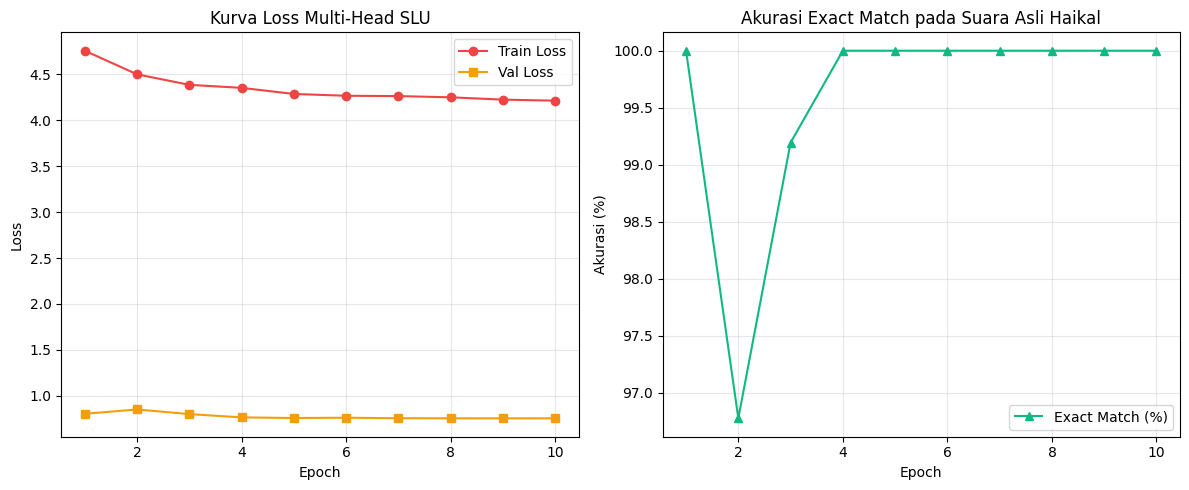

In [7]:
epochs_range = range(1, len(history['train_loss']) + 1)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='#ef4444', marker='o')
plt.plot(epochs_range, history['val_loss'], label='Val Loss', color='#f59e0b', marker='s')
plt.title('Kurva Loss Multi-Head SLU')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, [em * 100 for em in history['val_exact_match']], label='Exact Match (%)', color='#10b981', marker='^')
plt.title('Akurasi Exact Match pada Suara Asli Haikal')
plt.xlabel('Epoch')
plt.ylabel('Akurasi (%)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


## 8. Export Model ke Universal ONNX & Dynamic INT8 Quantization

In [3]:
import os
import sys
from pathlib import Path

# Pastikan working directory dan sys.path selalu mengarah ke root repository SVARA
root_dir = Path(os.getcwd()).resolve()
if root_dir.name == "notebooks":
    root_dir = root_dir.parent
    os.chdir(root_dir)
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from scripts.export_hardened_onnx import export_and_quantize_hardened

# Export checkpoint PyTorch terbaik ke Universal ONNX FP32 & Dynamic INT8
export_and_quantize_hardened(
    ckpt_path="models/svara_hardened.pt",
    output_fp32="models/svara_hardened.onnx",
    output_int8="models/svara_hardened_int8.onnx",
    output_meta="models/svara_hardened_int8.meta.json",
)


c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SUB-STEP 14.2: EXPORT ONNX FP32 & DYNAMIC INT8 QUANTIZATION


Loading weights: 100%|██████████| 211/211 [00:00<00:00, 29193.41it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.bias             | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[Export] Loading checkpoint from: models/svara_hardened.pt
[1/4] Exporting PyTorch graph to ONNX FP32: models/svara_hardened.onnx...


c:\Users\Axioo Pongo\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\integrations\sdpa_attention.py:136: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  is_causal = q_length > 1 and attention_mask is None and is_causal


  -> FP32 Graph Validated. File Size: 360.34 MB
[2/4] Applying Dynamic INT8 Quantization: models/svara_hardened_int8.onnx...


  -> INT8 Model Quantized. File Size: 90.87 MB (Compression: 3.97x)
[3/4] Writing Deployment Metadata: models/svara_hardened_int8.meta.json...
  -> Metadata saved successfully.
[4/4] Verifying Numerical Parity (PyTorch vs ONNX Runtime CPU)...
  - Test vector 1: max abs delta = 0.000000
  - Test vector 2: max abs delta = 0.000001

[Parity Result] Overall Maximum Numerical Difference: 0.000001
[STATUS] PASSED: Paritas numerik antara PyTorch dan ONNX Runtime terpenuhi sempurna!


('models/svara_hardened.onnx',
 'models/svara_hardened_int8.onnx',
 'models/svara_hardened_int8.meta.json',
 5.960464477539062e-07)

## 9. Live Interactive Voice Prediction Tester

In [6]:
import os
import sys
import pandas as pd
from pathlib import Path

# Pastikan working directory dan sys.path mengarah ke root SVARA
root_dir = Path(os.getcwd()).resolve()
if root_dir.name == "notebooks":
    root_dir = root_dir.parent
    os.chdir(root_dir)
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))

from svara.serve.inference import SLUInferenceEngine

# Inisialisasi Engine ONNX INT8 hasil training
engine = SLUInferenceEngine("models/svara_hardened_int8.onnx", "models/svara_hardened_int8.meta.json")

# Load metadata jika kernel baru direstart
if "df_own" not in globals() or df_own is None:
    df_own = pd.read_csv("data/own_recordings/metadata.csv")

# Uji 3 variasi tutur suara Haikal secara langsung
test_samples = [
    df_own[(df_own["intent_id"] == 1) & (df_own["style"] == "slang")].iloc[0],
    df_own[(df_own["intent_id"] == 20) & (df_own["style"] == "slang")].iloc[0],
    df_own[(df_own["intent_id"] == 26) & (df_own["style"] == "nyantai")].iloc[0],
]

print("=" * 75)
print("LIVE INFERENCE TESTER (SLU ONNX INT8 ENGINE)")
print("=" * 75)
for s in test_samples:
    with open(s["path"], "rb") as f:
        res = engine.predict_audio(f.read())
    pred = res["intent"]
    conf = res["confidence"]
    time_ms = res["timing_ms"]["total_ms"]
    target = f"{s['action']} {s['object']} {s['location']}"
    predicted = f"{pred['action']} {pred['object']} {pred['location']}"
    match_symbol = "✅ MATCH" if target == predicted else "❌ DIFF"
    print(f"Kalimat : '{s['transcript']}' ({s['style']})")
    print(f"Target  : ({target})")
    print(f"Hasil   : ({predicted}) [{match_symbol}] | Conf: {conf['overall']*100:.1f}% | Latensi: {time_ms:.1f}ms")
    print("-" * 75)


[SLUInferenceEngine] Loaded ONNX model from models/svara_hardened_int8.onnx
LIVE INFERENCE TESTER (SLU ONNX INT8 ENGINE)
Kalimat : 'Idupin lampu kamar tidur ya' (slang)
Target  : (activate lights bedroom)
Hasil   : (activate lights bedroom) [✅ MATCH] | Conf: 96.0% | Latensi: 2098.9ms
---------------------------------------------------------------------------
Kalimat : 'Stop musiknya sekarang ya' (slang)
Target  : (deactivate music none)
Hasil   : (deactivate music none) [✅ MATCH] | Conf: 95.9% | Latensi: 1313.2ms
---------------------------------------------------------------------------
Kalimat : 'Kamar dingin naikin suhunya dong' (nyantai)
Target  : (increase heat bedroom)
Hasil   : (increase heat bedroom) [✅ MATCH] | Conf: 96.2% | Latensi: 1751.7ms
---------------------------------------------------------------------------
